In [55]:
import pandas as pd
import numpy as np
from pathlib import Path

In [56]:
trips = pd.read_csv("./data/trips_eval.csv")
cities = pd.read_csv("./data/cities.csv")
bike_types = pd.read_csv("./data/bike_types.csv")
bikes = pd.read_csv("./data/bikes.csv")
stations = pd.read_csv("./data/stations_eval.csv")
stations_status = pd.read_csv("./data/stations_status_eval.csv")

In [57]:
# STATION MERGED
stations_merged = stations_status.merge(
    stations,
    how="left",
    left_on="station_id",
    right_on="id",
    validate="many_to_one",
    suffixes=("", "_station")
)

stations_merged = stations_merged.drop(columns=["id"])

stations_merged = stations_merged.merge(
    cities,
    how="left",
    left_on="city_id",
    right_on="id",
    validate="many_to_one",
    suffixes=("_station", "_city")
)

stations_merged = stations_merged.drop(columns=["id"])

stations_merged.to_csv(
    "./data/stations_merged.csv",
    index=False
)

In [58]:
# Convert Unix timestamp to UTC datetime
stations_merged["datetime"] = pd.to_datetime(
    stations_merged["time"],
    unit="s",
    origin="unix",
    utc=True
)

# Remove original time column
stations_merged.drop(
    columns=["time"],
    inplace=True
)

In [59]:
display(stations_merged.head(20))

,station_id,bikes,booked_bikes,bikes_available_to_rent,free_racks,free_special_racks,maintenance,city_id,name_station,app_number,...,rack_locks,lon_station,lat_station,name_city,lat_city,lon_city,timezone,country,return_to_official_only,datetime
0,5445382,9,0,9,7,7,False,450,Promenada/Amfiteatr,6332,...,NaN,19.128957,50.834213,Częstochowa,50.8120,19.13750,Europe/Warsaw,PL,True,2022-08-26 16:15:01+00:00
1,50401562,5,0,5,7,7,False,450,Pływalnia Kryta - MOSiR (al. Niepodległości),6356,...,NaN,19.132240,50.789740,Częstochowa,50.8120,19.13750,Europe/Warsaw,PL,True,2022-08-26 16:15:01+00:00
2,344835,9,0,9,3,0,False,266,Hauptbahnhof,2590,...,NaN,8.435215,49.478299,Ludwigshafen,49.4741,8.43287,Europe/Berlin,DE,True,2022-08-26 16:16:01+00:00
3,5445387,4,0,4,12,12,False,450,Okulickiego/Łódzka,6349,...,NaN,19.099592,50.823621,Częstochowa,50.8120,19.13750,Europe/Warsaw,PL,True,2022-08-26 16:16:01+00:00
4,5445396,11,0,11,5,5,False,450,Park Wodny,6334,...,NaN,19.119410,50.826100,Częstochowa,50.8120,19.13750,Europe/Warsaw,PL,True,2022-08-26 16:16:01+00:00
5,5445437,9,0,9,7,6,False,450,Plac Biegańskiego,6345,...,NaN,19.112628,50.812436,Częstochowa,50.8120,19.13750,Europe/Warsaw,PL,True,2022-08-26 16:16:01+00:00
6,77054807,16,0,16,0,0,False,773,Schwimmbad,32518,...,NaN,12.168385,47.589940,Kufstein,47.5830,12.16920,Europe/Berlin,AT,True,2022-08-26 16:16:01+00:00
7,66096550,3,0,3,0,0,False,709,Písek - roh Lesopark II,48395,...,NaN,14.163120,49.309718,Písek,49.3051,14.14630,Europe/Berlin,CZ,True,2022-08-26 16:17:01+00:00
8,77050029,0,0,0,7,0,False,773,Riedel Glas,32507,...,NaN,12.163223,47.574015,Kufstein,47.5830,12.16920,Europe/Berlin,AT,True,2022-08-26 16:17:01+00:00
9,77054807,15,0,15,0,0,False,773,Schwimmbad,32518,...,NaN,12.168385,47.589940,Kufstein,47.5830,12.16920,Europe/Berlin,AT,True,2022-08-26 16:17:01+00:00


In [60]:
# Check N/A value
stations_merged.isnull().sum()

station_id                      0
bikes                           0
booked_bikes                    0
bikes_available_to_rent         0
free_racks                      0
free_special_racks              0
maintenance                     0
city_id                         0
name_station                    0
app_number                      0
terminal_type                 576
place_type                      0
bike_racks                      0
special_racks                   0
rack_locks                 517787
lon_station                     0
lat_station                     0
name_city                       0
lat_city                        0
lon_city                        0
timezone                        0
country                         0
return_to_official_only         0
datetime                        0
dtype: int64

In [61]:
# Replace N/A value
stations_merged["terminal_type"] = stations_merged["terminal_type"].fillna("unknown")

In [62]:
# Check N/A value again
stations_merged.isnull().sum()

station_id                      0
bikes                           0
booked_bikes                    0
bikes_available_to_rent         0
free_racks                      0
free_special_racks              0
maintenance                     0
city_id                         0
name_station                    0
app_number                      0
terminal_type                   0
place_type                      0
bike_racks                      0
special_racks                   0
rack_locks                 517787
lon_station                     0
lat_station                     0
name_city                       0
lat_city                        0
lon_city                        0
timezone                        0
country                         0
return_to_official_only         0
datetime                        0
dtype: int64

In [63]:
# Sort data base on id and datetime
stations_merged = stations_merged.sort_values(
    ["station_id", "datetime"]
)
# Create tome_diff columns to show the gap between the previous data with the next one
stations_merged["time_diff"] = (
    stations_merged.groupby("station_id")["datetime"].diff()
)

In [64]:
display(stations_merged.head(20))

,station_id,bikes,booked_bikes,bikes_available_to_rent,free_racks,free_special_racks,maintenance,city_id,name_station,app_number,...,lon_station,lat_station,name_city,lat_city,lon_city,timezone,country,return_to_official_only,datetime,time_diff
9782,344835,9,0,9,3,0,False,266,Hauptbahnhof,2590,...,8.435215,49.478299,Ludwigshafen,49.4741,8.43287,Europe/Berlin,DE,True,2022-08-26 15:58:01+00:00,NaT
9814,344835,10,0,10,2,0,False,266,Hauptbahnhof,2590,...,8.435215,49.478299,Ludwigshafen,49.4741,8.43287,Europe/Berlin,DE,True,2022-08-26 16:08:01+00:00,0 days 00:10:00
2,344835,9,0,9,3,0,False,266,Hauptbahnhof,2590,...,8.435215,49.478299,Ludwigshafen,49.4741,8.43287,Europe/Berlin,DE,True,2022-08-26 16:16:01+00:00,0 days 00:08:00
309,344835,10,0,10,2,0,False,266,Hauptbahnhof,2590,...,8.435215,49.478299,Ludwigshafen,49.4741,8.43287,Europe/Berlin,DE,True,2022-08-26 18:18:01+00:00,0 days 02:02:00
889,344835,12,0,12,0,0,False,266,Hauptbahnhof,2590,...,8.435215,49.478299,Ludwigshafen,49.4741,8.43287,Europe/Berlin,DE,True,2022-08-27 07:04:01+00:00,0 days 12:46:00
923,344835,11,0,11,1,0,False,266,Hauptbahnhof,2590,...,8.435215,49.478299,Ludwigshafen,49.4741,8.43287,Europe/Berlin,DE,True,2022-08-27 07:29:01+00:00,0 days 00:25:00
1228,344835,12,0,12,0,0,False,266,Hauptbahnhof,2590,...,8.435215,49.478299,Ludwigshafen,49.4741,8.43287,Europe/Berlin,DE,True,2022-08-27 11:10:01+00:00,0 days 03:41:00
1230,344835,11,0,11,1,0,False,266,Hauptbahnhof,2590,...,8.435215,49.478299,Ludwigshafen,49.4741,8.43287,Europe/Berlin,DE,True,2022-08-27 11:11:01+00:00,0 days 00:01:00
1455,344835,12,0,12,0,0,False,266,Hauptbahnhof,2590,...,8.435215,49.478299,Ludwigshafen,49.4741,8.43287,Europe/Berlin,DE,True,2022-08-27 13:13:01+00:00,0 days 02:02:00
1540,344835,13,0,13,0,0,False,266,Hauptbahnhof,2590,...,8.435215,49.478299,Ludwigshafen,49.4741,8.43287,Europe/Berlin,DE,True,2022-08-27 14:04:01+00:00,0 days 00:51:00


In [65]:
# Check data types
print(stations_merged[["station_id", "datetime", "bikes_available_to_rent"]].dtypes)

# Check duplicated records
duplicate_count = stations_merged.duplicated(
    subset=["station_id", "datetime"]
).sum()

print("Duplicate records:", duplicate_count)

station_id                              int64
datetime                   datetime64[s, UTC]
bikes_available_to_rent                 int64
dtype: object
Duplicate records: 0


In [66]:
# Same datetime precision for both columns
stations_merged["datetime"] = stations_merged["datetime"].astype("datetime64[us, UTC]")

# Create target datetime (1 hour later)
stations_merged["target_datetime"] = (
    stations_merged["datetime"] + pd.Timedelta(hours=1)
)

In [67]:
# Create DataFrame for future data
future_data = stations_merged[
    ["station_id", "datetime", "bikes_available_to_rent"]
].rename(columns={
    "datetime": "target_observed_datetime",
    "bikes_available_to_rent": "target_bikes"
})

In [68]:
left_data = stations_merged.sort_values("target_datetime")
future_data = future_data.sort_values("target_observed_datetime")

In [69]:
# Take the last known state of the station at or before t + 1h
stations_with_target = pd.merge_asof(
    left_data,
    future_data,
    left_on="target_datetime",
    right_on="target_observed_datetime",
    by="station_id",
    direction="backward"      # no tolerance: the log only records changes
)

# Drop rows where t + 1h is beyond the end of the dataset (no ground truth yet)
data_end = stations_merged["datetime"].max()
stations_with_target = stations_with_target[
    stations_with_target["target_datetime"] <= data_end
]

stations_with_target = (
    stations_with_target
    .sort_values(["station_id", "datetime"])
    .reset_index(drop=True)
)

In [70]:
# No missing target expected
print("Missing target:", stations_with_target["target_bikes"].isna().sum())
print("Rows:", len(stations_with_target))

# How old is the observation used as target (should be >= 0)
staleness = (
    stations_with_target["target_datetime"]
    - stations_with_target["target_observed_datetime"]
)
print(staleness.describe())

# Baseline: predict "no change" after 1 hour
d_evt = (
    stations_with_target["target_bikes"]
    - stations_with_target["bikes_available_to_rent"]
)
mae_base = d_evt.abs().mean()
print("Baseline MAE (persistence, event-based):", mae_base)
print("Ti le delta == 0:", (d_evt == 0).mean())
print("MAE khi delta != 0:", d_evt[d_evt != 0].abs().mean())

Missing target: 0
Rows: 517702
count                    517702
mean     0 days 00:31:03.635606
std      0 days 00:23:53.336666
min             0 days 00:00:00
25%             0 days 00:07:00
50%             0 days 00:28:00
75%             0 days 01:00:00
max             0 days 01:00:00
dtype: object
Baseline MAE (persistence, event-based): 1.4182154984914102
Ti le delta == 0: 0.42495682844570815
MAE khi delta != 0: 2.4662765660847628


In [71]:
df = stations_with_target

print("Stations:", df["station_id"].nunique())
print("From:", df["datetime"].min())
print("To:", df["datetime"].max())
print("Days:", (df["datetime"].max() - df["datetime"].min()).days)

# Rows per station
print(df.groupby("station_id").size().describe())

# Share of rows where the target equals the current value
print("Unchanged after 1h:", (df["target_bikes"] == df["bikes_available_to_rent"]).mean())

# MAE of persistence per country
err = (df["target_bikes"] - df["bikes_available_to_rent"]).abs()
print(err.groupby(df["country"]).agg(["mean", "count"]))

Stations: 213
From: 2022-08-26 14:48:01+00:00
To: 2023-07-15 20:57:01+00:00
Days: 323
count      213.000000
mean      2430.525822
std       3557.858355
min          2.000000
25%        455.000000
50%       1112.000000
75%       2631.000000
max      21005.000000
dtype: float64
Unchanged after 1h: 0.42495682844570815
             mean   count
country                  
AT       0.934978   70668
CZ       0.513745   59294
DE       2.157322  126664
ES       1.684130   67056
GB       1.630352   72477
PL       1.096970  121543


In [72]:
MIN_EVENTS = 100

ev = stations_merged[
    ["station_id", "datetime", "bikes_available_to_rent", "free_racks"]
].copy()

# Drop stations with too few events
counts = ev.groupby("station_id").size()
ev = ev[ev["station_id"].isin(counts[counts >= MIN_EVENTS].index)]

# State at grid time T = last event with datetime <= T  ->  bucket by ceil("h")
ev["grid_time"] = ev["datetime"].dt.ceil("h")
ev = ev.sort_values(["station_id", "datetime"])
g = ev.groupby(["station_id", "grid_time"])
n_ev = g.size().rename("n_events")
ev = (
    g[["bikes_available_to_rent", "free_racks"]].last()
      .join(n_ev)
      .reset_index()
)

hours = pd.date_range(
    ev["grid_time"].min(),
    stations_merged["datetime"].max().ceil("h"),
    freq="h"
)

def to_wide(col):
    return (
        ev.pivot(index="grid_time", columns="station_id", values=col)
          .reindex(hours)
          .astype("float32")
    )

bikes_raw = to_wide("bikes_available_to_rent").ffill()
racks_raw = to_wide("free_racks").ffill()
ev_cnt = to_wide("n_events").fillna(0)

print("stations:", bikes_raw.shape[1])

stations: 202


AT: 2022-09-17 15:00 -> 2022-09-19 12:00  (46h)
AT: 2022-10-17 14:00 -> 2022-10-18 12:00  (23h)
AT: 2023-01-22 00:00 -> 2023-01-22 23:00  (24h)
AT: 2023-05-05 11:00 -> 2023-05-17 08:00  (286h)
AT: 2023-06-26 20:00 -> 2023-06-27 07:00  (12h)
CZ: 2022-09-17 15:00 -> 2022-09-19 12:00  (46h)
CZ: 2022-10-17 14:00 -> 2022-10-18 12:00  (23h)
CZ: 2022-11-19 00:00 -> 2022-11-20 23:00  (48h)
CZ: 2022-12-03 00:00 -> 2022-12-03 23:00  (24h)
CZ: 2022-12-10 00:00 -> 2023-03-01 11:00  (1956h)
CZ: 2023-05-05 11:00 -> 2023-05-17 08:00  (286h)
CZ: 2023-06-26 20:00 -> 2023-06-27 07:00  (12h)
DE: 2022-09-17 15:00 -> 2022-09-19 12:00  (46h)
DE: 2022-10-17 14:00 -> 2022-10-18 12:00  (23h)
DE: 2022-12-26 00:00 -> 2022-12-26 23:00  (24h)
DE: 2023-05-05 11:00 -> 2023-05-17 08:00  (286h)
DE: 2023-06-26 20:00 -> 2023-06-27 07:00  (12h)
ES: 2022-08-26 15:00 -> 2023-01-30 06:00  (3760h)
ES: 2023-05-05 11:00 -> 2023-05-17 08:00  (286h)
ES: 2023-06-26 20:00 -> 2023-06-27 07:00  (12h)
GB: 2022-09-17 15:00 -> 2022-09-

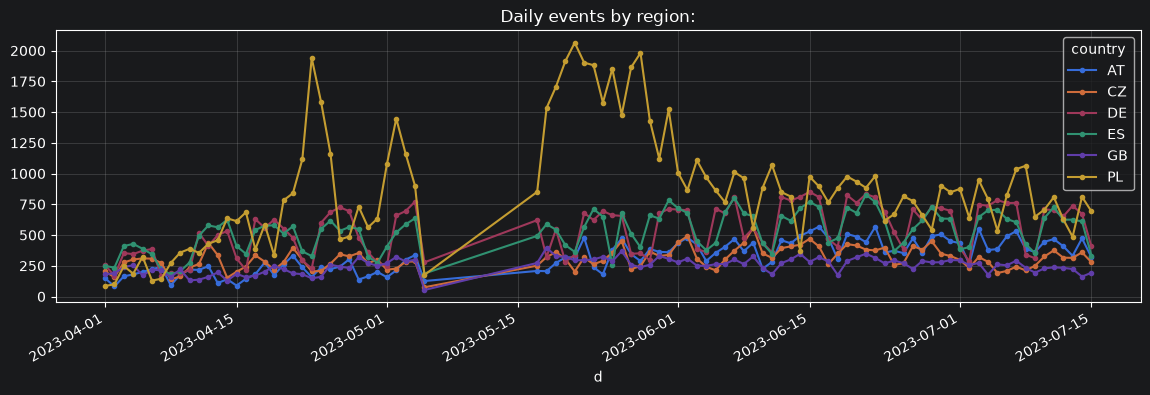

In [73]:
import matplotlib.pyplot as plt

MIN_GAP_H = 12
MIN_RATE = 1.0
MIN_COV = 0.30

sid2country = stations_merged.drop_duplicates("station_id").set_index("station_id")["country"]
ctry = sid2country.loc[bikes_raw.columns].values

# Number of events per hour by country
ev_h = ev_cnt.T.groupby(ctry).sum().T

def long_zero_runs(s, min_len):
    z = (s.values == 0)
    grp = np.cumsum(np.r_[True, z[1:] != z[:-1]])
    run_len = pd.Series(z).groupby(grp).transform("size").values
    return z & (run_len >= min_len)

out_zero = pd.DataFrame(
    {c: long_zero_runs(ev_h[c], MIN_GAP_H) for c in ev_h.columns},
    index=hours
)

# Detection of "partial" outages by date
day = hours.floor("D")
n_st = pd.Series(ctry).value_counts().reindex(ev_h.columns)
rate_d = ev_h.groupby(day).sum().div(n_st, axis=1)            # event / station / day
cov_d = (ev_cnt > 0).groupby(day).any().T.groupby(ctry).mean().T.reindex(columns=rate_d.columns)

out_low = ((rate_d < MIN_RATE) | (cov_d < MIN_COV)).reindex(day)
out_low.index = hours

out_c = out_zero | out_low

# Print out the log gaps
for c in out_c.columns:
    s = out_c[c]
    starts = s & ~s.shift(1, fill_value=False)
    ends   = s & ~s.shift(-1, fill_value=False)
    for a, b in zip(s.index[starts], s.index[ends]):
        print(f"{c}: {a:%Y-%m-%d %H:%M} -> {b:%Y-%m-%d %H:%M}  ({(b - a).total_seconds() / 3600 + 1:.0f}h)")

# Expanding from the country to the station
bad = out_c[ctry].copy()
bad.columns = bikes_raw.columns            # hours x stations (bool)

# Valid = not within an outage and the station has recorded at least one event since the most recent outage
idx = np.arange(len(hours))[:, None]
has_ev = (ev_cnt.values > 0) & ~bad.values
last_ev = np.maximum.accumulate(np.where(has_ev,     idx, -1), axis=0)
last_bad = np.maximum.accumulate(np.where(bad.values, idx, -1), axis=0)
valid = (last_ev > last_bad) & ~bad.values
valid_df = pd.DataFrame(valid, index=hours, columns=bikes_raw.columns)

bikes_w = bikes_raw.where(valid_df)
racks_w = racks_raw.where(valid_df)
n_events = ev_cnt.mask(bad)

hours_since = pd.DataFrame(
    np.where(valid, idx - last_ev, np.nan).astype("float32"),
    index=hours, columns=bikes_raw.columns
)

print("Percentage of station-hours flagged as missing logs:", bad.values.mean())
print("Percentage of station-hours invalid (outage + stale):", (~valid).mean())

daily = (
    stations_merged
    .assign(d=stations_merged["datetime"].dt.tz_localize(None).dt.floor("D"))
    .groupby(["d", "country"]).size().unstack("country").fillna(0)
)
daily.loc["2023-04-01":"2023-07-15"].plot(figsize=(14, 4), marker=".")
plt.title("Daily events by region:"); plt.grid(alpha=0.3); plt.show()

In [74]:
# Features on the wide matrix (for past data only)
f = {"bikes_now": bikes_w, "free_racks": racks_w}
for h in [1, 2, 3, 24, 168]:
    f[f"lag_{h}h"] = bikes_w.shift(h)
f["diff_1h"] = bikes_w - bikes_w.shift(1)
f["roll_mean_3h"] = bikes_w.rolling(3).mean()
f["roll_mean_24h"] = bikes_w.rolling(24).mean()
f["roll_std_24h"] = bikes_w.rolling(24).std()
f["roll_min_24h"] = bikes_w.rolling(24).min()
f["roll_max_24h"] = bikes_w.rolling(24).max()

# Add activity feature + change compared to the same time yesterday / last week (past data only)
f["n_events_1h"] = n_events
f["n_events_24h"] = n_events.rolling(24, min_periods=1).sum()
f["hours_since_evt"] = hours_since
f["lastweek_delta"] = bikes_w.shift(167) - bikes_w.shift(168)
f["yesterday_delta"] = bikes_w.shift(23)  - bikes_w.shift(24)

# Bikes available 1 hour later
target = bikes_w.shift(-1)

T, S = bikes_w.shape
station_ids = bikes_w.columns.values

df = pd.DataFrame({k: v.values.ravel() for k, v in f.items()})
df["target"] = target.values.ravel()
df["station_id"] = np.tile(station_ids, T)
df["datetime"] = hours.repeat(S)

# Static station info
st = (
    stations_merged.drop_duplicates("station_id")
    .set_index("station_id")
    .loc[station_ids]
)
for col in ["country", "terminal_type", "place_type", "city_id"]:
    df[col] = np.tile(st[col].astype("category").cat.codes.values, T)
for col in ["bike_racks", "lat_station", "lon_station"]:
    df[col] = np.tile(st[col].values.astype("float32"), T)

# Local time features (for each timezone)
tz_cat = st["timezone"].astype("category")
hour_lut = np.stack([hours.tz_convert(tz).hour.values for tz in tz_cat.cat.categories])
dow_lut = np.stack([hours.tz_convert(tz).dayofweek.values for tz in tz_cat.cat.categories])
codes = tz_cat.cat.codes.values
df["hour"] = hour_lut[codes].T.ravel().astype("int8")
df["dow"]  = dow_lut[codes].T.ravel().astype("int8")
df["is_weekend"] = (df["dow"] >= 5).astype("int8")
df["hour_sin"] = np.sin(2 * np.pi * df["hour"] / 24).astype("float32")
df["hour_cos"] = np.cos(2 * np.pi * df["hour"] / 24).astype("float32")

# Derived features
df["capacity_est"] = df["bikes_now"] + df["free_racks"]
df["fill_ratio"] = (df["bikes_now"] / df["capacity_est"].replace(0, np.nan)).astype("float32")

# Keep only rows that have both the current state and the target
df = df.dropna(subset=["bikes_now", "target"]).reset_index(drop=True)
df["delta"] = (df["target"] - df["bikes_now"]).astype("float32")
df["active"] = df["n_events_24h"] > 0   #For evaluation purposes only; NOT included in features

print(df.shape)

(1171914, 37)


In [75]:
# Train/Validation/Test split
val_start = pd.Timestamp("2023-05-01", tz="UTC")
test_start = pd.Timestamp("2023-06-01", tz="UTC")

train = df[df["datetime"] < val_start]
val = df[
    (df["datetime"] >= val_start) &
    (df["datetime"] < test_start)
]
test = df[df["datetime"] >= test_start]

# Features and target
features = [
    c for c in df.columns
    if c not in ["target", "delta", "datetime", "station_id", "active"] #Add active
]

#Use the same training sample for all models
train_s = train

# A shared evaluation function for each model
def report(name, d, pred):
    err = np.abs(d["target"].values - pred)
    base = np.abs(d["delta"].values)                  # persistence error
    masks = {
        "all": np.ones(len(d), dtype=bool),
        "active": d["active"].values,
        "changed": d["delta"].values != 0,
    }
    for tag, m in masks.items():
        e, b = err[m].mean(), base[m].mean()
        print(f"{name:10s} {tag:8s} MAE={e:.4f}  persist={b:.4f}  skill={1 - e / b:+.2%}")

# Station capacity and a helper to post-process predictions
def cap_of(d):
    c = (d["bikes_now"] + d["free_racks"]).values.astype("float64")
    return np.where(np.isnan(c), np.inf, c)

cap_val, cap_test = cap_of(val), cap_of(test)

def finalize(d, delta_pred, cap, rnd=True):
    p = d["bikes_now"].values + delta_pred
    if rnd:
        p = np.round(p)          # bikes are integers
    return np.clip(p, 0, cap)    # 0 <- bikes <- capacity

#Baselines: persistence and "same time last week"
for nm, d in [("val", val), ("test", test)]:
    persist = d["bikes_now"].values
    weekly = np.clip(d["bikes_now"].values + d["lastweek_delta"].fillna(0).values, 0, None)
    report(f"persist-{nm}", d, persist)
    report(f"weekly-{nm}", d, weekly)

print("Train:", train_s.shape)
print("Validation:", val.shape)
print("Test:", test.shape)


persist-val all      MAE=0.3588  persist=0.3588  skill=+0.00%
persist-val active   MAE=0.4132  persist=0.4132  skill=+0.00%
persist-val changed  MAE=1.7466  persist=1.7466  skill=+0.00%
weekly-val all      MAE=0.4374  persist=0.3588  skill=-21.91%
weekly-val active   MAE=0.5018  persist=0.4132  skill=-21.43%
weekly-val changed  MAE=1.7225  persist=1.7466  skill=+1.38%
persist-test all      MAE=0.3844  persist=0.3844  skill=+0.00%
persist-test active   MAE=0.4293  persist=0.4293  skill=+0.00%
persist-test changed  MAE=1.7279  persist=1.7279  skill=+0.00%
weekly-test all      MAE=0.5331  persist=0.3844  skill=-38.67%
weekly-test active   MAE=0.5923  persist=0.4293  skill=-37.97%
weekly-test changed  MAE=1.7160  persist=1.7279  skill=+0.69%
Train: (868933, 37)
Validation: (90044, 37)
Test: (212937, 37)


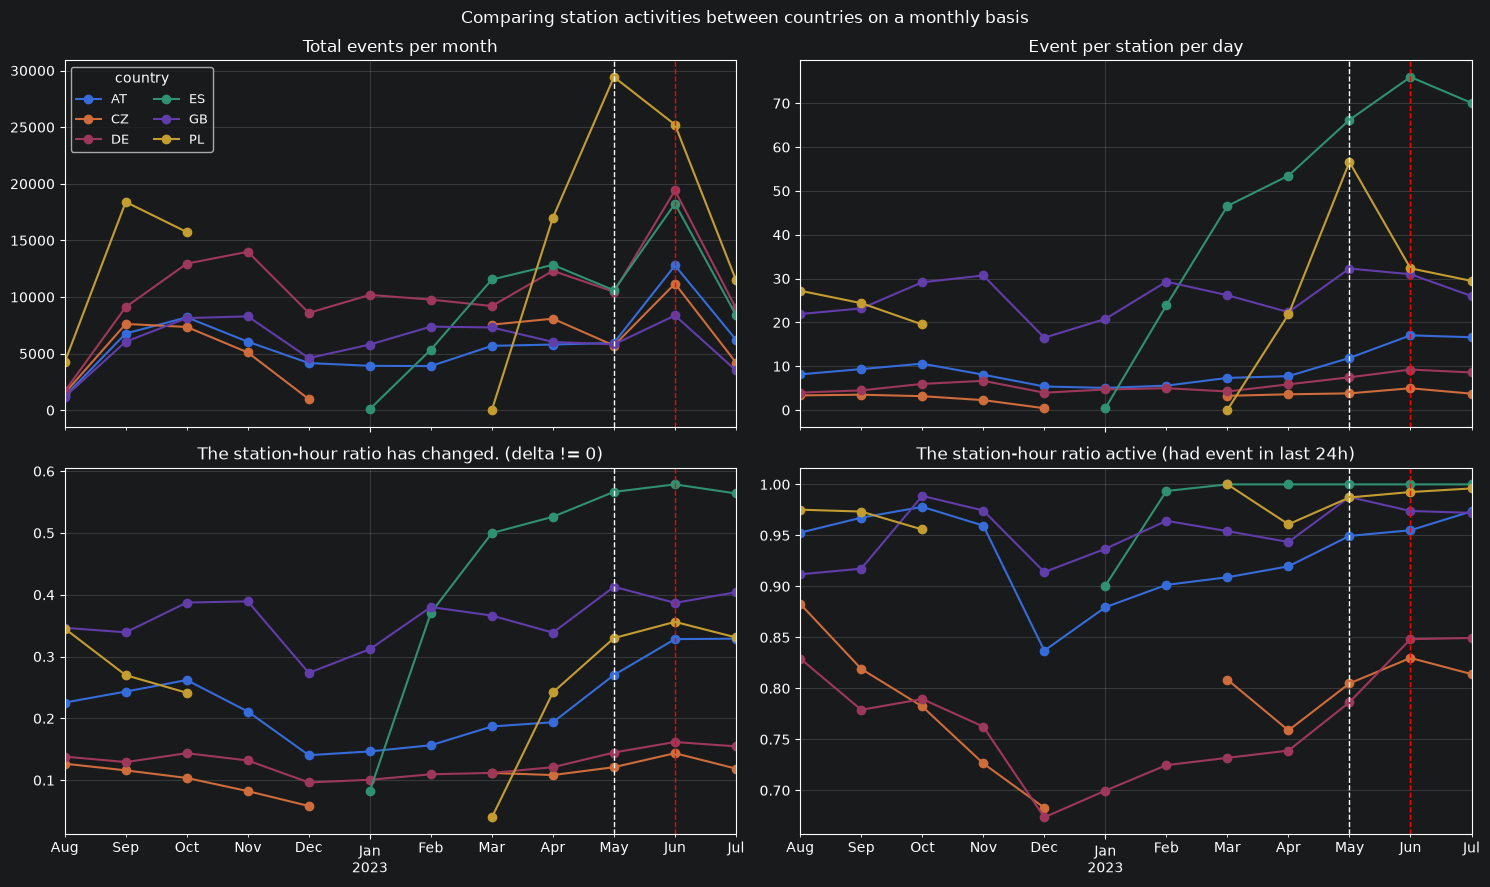

In [76]:
import matplotlib.pyplot as plt

#Prepare data
e = stations_merged[["station_id", "country", "datetime"]].copy()
e["month"] = e["datetime"].dt.tz_localize(None).dt.to_period("M")

# Total number of events per month by country
cnt = e.groupby(["month", "country"]).size().unstack("country")

# Normalization: events / station / day (the first and last months contain only partial data)
days = e.assign(d=e["datetime"].dt.date).groupby("month")["d"].nunique()
n_st = e.groupby("country")["station_id"].nunique()
rate = cnt.div(days, axis=0).div(n_st, axis=1)

# The number of stations "changed" and "active" from time to time (df)
cats = st["country"].astype("category").cat.categories      # map code -> ten nuoc
g = df.assign(
    country_name=df["country"].map(dict(enumerate(cats))),
    month=df["datetime"].dt.tz_localize(None).dt.to_period("M"),
    changed=df["delta"] != 0,
)
chg = g.groupby(["month", "country_name"])["changed"].mean().unstack()
act = g.groupby(["month", "country_name"])["active"].mean().unstack()

for t in (cnt, rate, chg, act):
    t.index = t.index.to_timestamp()

fig, axes = plt.subplots(2, 2, figsize=(15, 9), sharex=True)
panels = [
    (cnt, "Total events per month", axes[0, 0]),
    (rate, "Event per station per day", axes[0, 1]),
    (chg, "The station-hour ratio has changed. (delta != 0)", axes[1, 0]),
    (act, "The station-hour ratio active (had event in last 24h)", axes[1, 1]),
]
v0 = val_start.tz_localize(None)
t0 = test_start.tz_localize(None)

for t, title, ax in panels:
    t.plot(ax=ax, marker="o", legend=False)
    ax.axvline(v0, color="white", ls="--", lw=1)     # starting val
    ax.axvline(t0, color="red",  ls="--", lw=1)     # starting test
    ax.set_title(title)
    ax.grid(alpha=0.3)
    ax.set_xlabel("")

axes[0, 0].legend(title="country", ncol=2, fontsize=9)
fig.suptitle("Comparing station activities between countries on a monthly basis")
plt.tight_layout()
plt.show()

In [77]:
#Calculate correlation between features and DELTA
corr = df[features + ["delta"]].corr(numeric_only=True)
target_corr = corr["delta"].sort_values(ascending=False)

print(target_corr)

delta              1.000000
lastweek_delta     0.277774
yesterday_delta    0.234919
diff_1h            0.110570
free_racks         0.062539
hour_cos           0.008902
hour               0.006174
hours_since_evt    0.003787
country            0.000262
bike_racks         0.000181
terminal_type      0.000123
lat_station       -0.000085
place_type        -0.000085
city_id           -0.000180
lon_station       -0.000260
is_weekend        -0.000568
dow               -0.000725
n_events_24h      -0.002901
n_events_1h       -0.006906
hour_sin          -0.008323
roll_std_24h      -0.010362
lag_168h          -0.025461
capacity_est      -0.032358
roll_max_24h      -0.032369
roll_mean_24h     -0.034034
lag_24h           -0.036426
roll_min_24h      -0.038110
fill_ratio        -0.072756
bikes_now         -0.086464
roll_mean_3h      -0.102927
lag_1h            -0.105931
lag_2h            -0.113965
lag_3h            -0.114239
Name: delta, dtype: float64


In [78]:
#Testing LightGBM
import lightgbm as lgb

cat_features = [
    "country", "terminal_type", "place_type", "city_id"
]

lgb_model = lgb.LGBMRegressor(
    objective="regression_l1",
    learning_rate=0.05,
    n_estimators=2000,
    num_leaves=127,
    min_child_samples=100,
    subsample=0.8,
    subsample_freq=1,
    colsample_bytree=0.8,
    n_jobs=-1
)

# Train
lgb_model.fit(
    train_s[features],
    train_s["delta"],
    eval_set=[(val[features], val["delta"])],
    eval_metric="l1",
    categorical_feature=cat_features,
    callbacks=[
        lgb.early_stopping(100),
        lgb.log_evaluation(100)
    ]
)

# Prediction
pred_lgb_val = np.clip(
    val["bikes_now"].values + lgb_model.predict(val[features]), 0, None
)
pred_lgb = np.clip(
    test["bikes_now"].values + lgb_model.predict(test[features]), 0, None
)

report("lgbm-val", val, pred_lgb_val)
report("lgbm-test", test, pred_lgb)

mae_lgb = np.mean(np.abs(test["target"].values - pred_lgb))
print("LightGBM MAE:", mae_lgb)


D:\ML\Challenge-IMT\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.034809 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2744
[LightGBM] [Info] Number of data points in the train set: 868933, number of used features: 32
Training until validation scores don't improve for 100 rounds
[100]	valid_0's l1: 0.348474
[200]	valid_0's l1: 0.347401
[300]	valid_0's l1: 0.347157
[400]	valid_0's l1: 0.347068
[500]	valid_0's l1: 0.347001
Early stopping, best iteration is:
[495]	valid_0's l1: 0.34699
lgbm-val   all      MAE=0.3470  persist=0.3588  skill=+3.28%
lgbm-val   active   MAE=0.3994  persist=0.4132  skill=+3.33%
lgbm-val   changed  MAE=1.6485  persist=1.7466  skill=+5.62%
lgbm-test  all      MAE=0.3712  persist=0.3844  skill=+3.43%
lgbm-test  active   MAE=0.4143  persist=0.4293  skill=+3.48%
lgbm-test  changed  MAE=1.6202  persist=1.7279  skill=+6.24%
LightGBM M

In [79]:
# Test for Hist Gradient Boosting Regressor
from sklearn.ensemble import HistGradientBoostingRegressor

cat_mask = [c in cat_features for c in features]

hgb_model = HistGradientBoostingRegressor(
    loss="absolute_error",
    learning_rate=0.05,
    max_iter=500,
    max_leaf_nodes=63,
    min_samples_leaf=100,
    categorical_features=cat_mask,
    early_stopping=False,
    random_state=0
)

# Train
hgb_model.fit(train_s[features], train_s["delta"])

# Prediction
pred_hgb = np.clip(
    test["bikes_now"].values + hgb_model.predict(test[features]),
    0,
    None
)

report("hgb-test", test, pred_hgb)

mae_hgb = np.mean(np.abs(test["target"].values - pred_hgb))
print("HistGB MAE:", mae_hgb)

hgb-test   all      MAE=0.3802  persist=0.3844  skill=+1.10%
hgb-test   active   MAE=0.4245  persist=0.4293  skill=+1.12%
hgb-test   changed  MAE=1.6950  persist=1.7279  skill=+1.91%
HistGB MAE: 0.38017599765855303


In [80]:
# Test for XGBoost
from xgboost import XGBRegressor

xgb_model = XGBRegressor(
    n_estimators=2000,
    learning_rate=0.05,
    max_depth=8,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:absoluteerror", # replace reg:squarederror with reg:absoluteerror
    random_state=0,
    n_jobs=-1
)

# Train
xgb_model.fit(
    train_s[features],
    train_s["delta"],
    eval_set=[(val[features], val["delta"])],
    verbose=100
)

# Prediction
pred_xgb = np.clip(
    test["bikes_now"].values + xgb_model.predict(test[features]),
    0,
    None
)

mae_xgb = np.mean(
    np.abs(test["target"].values - pred_xgb)
)

report("xgb-test", test, pred_xgb)

mae_xgb = np.mean(np.abs(test["target"].values - pred_xgb))
print("XGBoost MAE:", mae_xgb)

[0]	validation_0-mae:0.35877
[100]	validation_0-mae:0.35522
[200]	validation_0-mae:0.35330
[300]	validation_0-mae:0.35231
[400]	validation_0-mae:0.35177
[500]	validation_0-mae:0.35152
[600]	validation_0-mae:0.35130
[700]	validation_0-mae:0.35100
[800]	validation_0-mae:0.35087
[900]	validation_0-mae:0.35083
[1000]	validation_0-mae:0.35080
[1100]	validation_0-mae:0.35073
[1200]	validation_0-mae:0.35065
[1300]	validation_0-mae:0.35058
[1400]	validation_0-mae:0.35050
[1500]	validation_0-mae:0.35045
[1600]	validation_0-mae:0.35041
[1700]	validation_0-mae:0.35030
[1800]	validation_0-mae:0.35022
[1900]	validation_0-mae:0.35016
[1999]	validation_0-mae:0.35008
xgb-test   all      MAE=0.3729  persist=0.3844  skill=+3.01%
xgb-test   active   MAE=0.4160  persist=0.4293  skill=+3.08%
xgb-test   changed  MAE=1.6394  persist=1.7279  skill=+5.12%
XGBoost MAE: 0.37285808
